# importation des bibliotheques 

In [ ]:
%pip install pandas,numpy,matplotlib

Note: you may need to restart the kernel to use updated packages.


ERROR: Invalid requirement: 'pandas,numpy,matplotlib': Expected semicolon (after name with no version specifier) or end
    pandas,numpy,matplotlib
          ^


In [27]:
%pip install clustpy

  Using cached clustpy-0.0.3.tar.gz (2.4 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached torch-2.15.0-cp314-cp314-win_amd64.whl.metadata (36 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
Using cached torch-2.15.0-cp314-cp314-win_amd64.whl (126.7 MB)
Using cached torchvision-0.29.2-py3-none-win_amd64.whl (1.4 MB)
Failed to build clustpy
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Building wheel for clustpy (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [173 lines of output]
      C:\Users\User\AppData\Local\Temp\pip-build-env-v_h90c3_\overlay\Lib\site-packages\setuptools\config\_apply_pyprojecttoml.py:82: SetuptoolsDeprecationWarning: `project.license` as a TOML table is deprecated
      !!
      
              ********************************************************************************
              Please use a simple string containing a SPDX expression for `project.license`. You can also use `project.license-files`. (Both options available on setuptools>=77.0.0).
      
              By 2027-Feb-18, you need to update your project and remove deprecated calls
              or your builds will no longer be supported.
      
              See https://packaging.python.org/en/latest/guides/writing-pyproject-toml/#license for details.
              *************************************************

In [ ]:
%pip install scipy,sklearn


Note: you may need to restart the kernel to use updated packages.


ERROR: Invalid requirement: 'scipy,sklearn': Expected semicolon (after name with no version specifier) or end
    scipy,sklearn
         ^


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.io import arff
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt
from clustpy.hierarchical.diana import Diana

ModuleNotFoundError: No module named 'clustpy'

###  1-lire et afficher le dataset


In [ ]:

data, meta= arff.loadarff("hypothyroid.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,41.0,F,f,f,f,f,f,f,f,f,...,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,...,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,...,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,...,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,...,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,negative
3768,68.0,F,f,f,f,f,f,f,f,f,...,t,124.0,t,1.08,t,114.0,f,NaN,SVI,negative
3769,74.0,F,f,f,f,f,f,f,f,f,...,t,112.0,t,1.07,t,105.0,f,NaN,other,negative
3770,72.0,M,f,f,f,f,f,f,f,f,...,t,82.0,t,0.94,t,87.0,f,NaN,SVI,negative


### 1. Identifier et supprimer les attributs ayant plus de 70 % de valeurs manquantes

In [ ]:
# Calculer le pourcentage de valeurs manquantes
pourcentage_nan = df.isnull().mean() * 100

# Identifier les attributs ayant plus de 70% de valeurs manquantes
cln_vides = pourcentage_nan[pourcentage_nan > 70].index.tolist()
# Supprimer ces attributs

df = df.drop(columns=cln_vides)
print("Attributs  supprimée :", cln_vides)

Attributs  supprimée : ['TBG']


### Supprission des doublons:

In [ ]:
df = df.drop_duplicates()

### Sélection des attributs numériques

In [ ]:
numeriques_df = df.select_dtypes(include=np.number).copy()


### remplacement des valeurs manquantes par la mediane 

In [ ]:
numeriques_df = numeriques_df.fillna(numeriques_df.median())

print("Valeurs manquantes restantes :")
print(numeriques_df.isnull().sum().sum())

Valeurs manquantes restantes :
0


### Remplacement des outliers par lim inf ou lim sup

In [ ]:

for col in numeriques_df.columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    # Remplacer les outliers par les limites
    df[col] = df[col].clip(lower=limite_inf, upper=limite_sup)

#### Z-score :

In [ ]:
# Standardisation
scaler = StandardScaler()
scaled_dataset = scaler.fit_transform(numeriques_df)

# Convertir le résultat en DataFrame
scaled_dataset = pd.DataFrame(
    scaled_dataset,
    columns=numeriques_df.columns
)

display(scaled_dataset)

,age,TSH,T3,TT4,T4U,FTI
0,-0.566032,-0.334505,0.838870,0.600304,0.968711,-0.008410
1,-1.512140,1.220954,0.028712,-0.169899,-0.039662,-0.086429
2,-0.303224,-0.512272,0.028712,0.064511,-0.480825,0.420696
3,0.958253,-0.967799,-0.133319,2.274658,-0.039662,-0.086429
4,0.958253,-0.656707,-1.267539,-1.542869,-0.732918,-1.529785
...,...,...,...,...,...,...
3706,-1.144209,-0.278953,0.028712,-0.136412,-0.039662,-0.086429
3707,0.853130,-0.501161,0.190744,0.566817,0.590572,0.186639
3708,1.168499,1.776475,-0.295350,0.164972,0.527548,-0.164448
3709,1.063376,-0.667818,0.028712,-0.839640,-0.291755,-0.866621


## courbe d'elbow

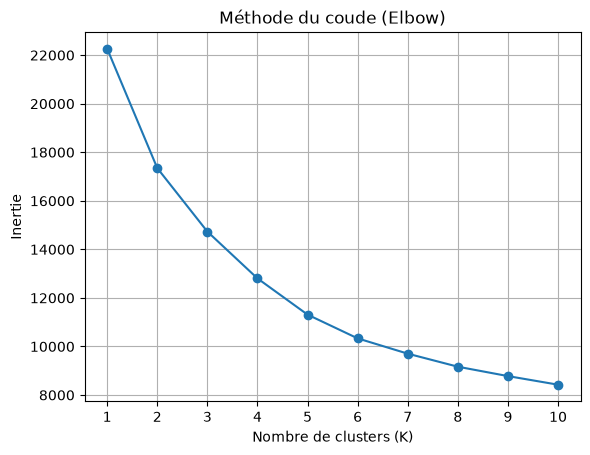

In [ ]:
inerties = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_dataset)

    inerties.append(kmeans.inertia_)

# Tracer la courbe Elbow
plt.plot(range(1, 11), inerties, marker='o')
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude (Elbow)")
plt.xticks(range(1, 11))
plt.grid()
plt.show()



d'apres la courbe on trouve que k=3

## 3.Application des algorithmes de clustering hiérarchique :

### 3.1 AGNES

**application de l algo**

In [ ]:
Z = linkage(scaled_dataset, method='ward')

**Afficher le dendrogramme**
visualiser comment les observations sont fusionnées progressivement.

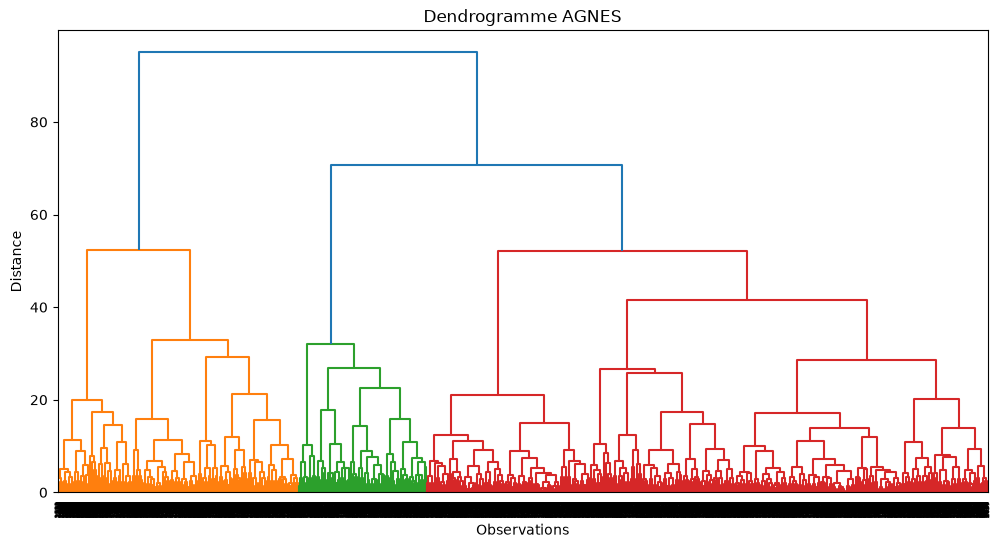

In [ ]:
Z = linkage(scaled_dataset, method='ward')
plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.title("Dendrogramme AGNES")
plt.xlabel("Observations")
plt.ylabel("Distance")
plt.show()

**Extraire les clusters**

In [ ]:
clusters_agnes = fcluster(Z, t=3, criterion='maxclust')


print("\nNombre d'observations par cluster :")
print(pd.Series(clusters_agnes).value_counts().sort_index())


Nombre d'observations par cluster :
1     963
2     509
3    2239
Name: count, dtype: int64


### 3.2 DIANA 

In [ ]:


# Créer le modèle DIANA
diana = Diana(n_clusters=3)

# Appliquer l'algorithme
diana.fit(scaled_dataset.to_numpy())

# Récupérer les clusters
clusters_diana = diana.labels_

# Afficher la répartition
print(pd.Series(clusters_diana).value_counts().sort_index())